In [1]:
!pip install transformers torch scikit-learn nltk -q

In [2]:
import json
import random
import numpy as np
import torch
import nltk
from nltk.stem import WordNetLemmatizer
from nltk.tokenize import word_tokenize
from sklearn.metrics.pairwise import cosine_similarity
from transformers import AutoTokenizer, AutoModel
import warnings
warnings.filterwarnings('ignore')

nltk.download('punkt', quiet=True)
nltk.download('wordnet', quiet=True)
nltk.download('stopwords', quiet=True)
nltk.download('punkt_tab', quiet=True)

print("✅ All libraries imported successfully!")

✅ All libraries imported successfully!


In [3]:
intents = [
    {
        "tag": "greeting",
        "patterns": ["hello", "hi", "hey", "good morning", "good evening", "what's up", "howdy"],
        "responses": [
            "Hello! I'm your NLP assistant. Ask me anything about NLP or AI!",
            "Hi there! Ready to explore the world of NLP and AI with you!",
            "Hey! I'm here to answer your NLP and AI questions."
        ]
    },
    {
        "tag": "goodbye",
        "patterns": ["bye", "goodbye", "see you", "quit", "exit", "thanks bye"],
        "responses": [
            "Goodbye! Happy learning!",
            "See you later! Keep exploring NLP!",
            "Bye! Feel free to come back anytime."
        ]
    },
    {
        "tag": "what_is_nlp",
        "patterns": ["what is nlp", "explain nlp", "define natural language processing",
                     "what does nlp mean", "tell me about nlp", "nlp meaning"],
        "responses": [
            "NLP stands for Natural Language Processing. It is a branch of AI that enables computers to understand, interpret, and generate human language. Examples include chatbots, translation tools, and sentiment analysis.",
            "Natural Language Processing (NLP) is a field at the intersection of linguistics, computer science, and AI. It helps machines read, understand, and respond to human language."
        ]
    },
    {
        "tag": "tokenization",
        "patterns": ["what is tokenization", "explain tokenization", "how does tokenization work",
                     "what are tokens", "tokenize text"],
        "responses": [
            "Tokenization is the process of splitting text into smaller units called tokens (words, subwords, or characters). For example: 'I love NLP' → ['I', 'love', 'NLP'].",
            "Tokenization breaks text into tokens — the basic units of NLP. Word tokenization splits by spaces/punctuation, while subword tokenization (used by BERT) splits rare words into pieces."
        ]
    },
    {
        "tag": "stemming_lemmatization",
        "patterns": ["what is stemming", "what is lemmatization", "difference between stemming and lemmatization",
                     "explain lemmatization", "stemming vs lemmatization"],
        "responses": [
            "Stemming reduces words to their root form by chopping off suffixes (e.g., 'running' → 'run'). Lemmatization uses vocabulary and morphological analysis to return the base dictionary form (e.g., 'better' → 'good').",
            "Both normalize words. Stemming is faster but cruder. Lemmatization is more accurate — it uses context (POS tags) to find the true root word."
        ]
    },
    {
        "tag": "sentiment_analysis",
        "patterns": ["what is sentiment analysis", "explain sentiment analysis", "how does sentiment analysis work",
                     "opinion mining", "sentiment detection"],
        "responses": [
            "Sentiment analysis is the process of determining the emotional tone (positive, negative, neutral) of text. It is widely used in product reviews, social media monitoring, and customer feedback.",
            "Sentiment analysis uses NLP and ML to classify opinions in text. Modern approaches use transformers like BERT to achieve high accuracy."
        ]
    },
    {
        "tag": "word_embeddings",
        "patterns": ["what are word embeddings", "explain word2vec", "what is glove", "word vectors",
                     "word representation", "what is embedding"],
        "responses": [
            "Word embeddings are dense vector representations of words in a continuous space where semantically similar words are closer together. Popular methods include Word2Vec, GloVe, and FastText.",
            "Word2Vec learns word vectors by predicting context words (Skip-gram) or predicting a word from its context (CBOW). GloVe uses global co-occurrence statistics. Both capture semantic relationships."
        ]
    },
    {
        "tag": "transformer",
        "patterns": ["what is a transformer", "explain transformer model", "how does bert work",
                     "what is attention mechanism", "self-attention", "transformer architecture"],
        "responses": [
            "The Transformer architecture (2017) uses self-attention mechanisms to process all tokens in parallel. It powers models like BERT, GPT, and T5. BERT is pre-trained on masked language modeling and next sentence prediction.",
            "Transformers use multi-head self-attention to weigh the importance of each word relative to others in a sentence, allowing deep contextual understanding without sequential processing."
        ]
    },
    {
        "tag": "named_entity_recognition",
        "patterns": ["what is ner", "named entity recognition", "explain ner",
                     "how to identify entities", "entity extraction"],
        "responses": [
            "Named Entity Recognition (NER) identifies and classifies named entities in text into categories like Person, Organization, Location, Date, etc. Example: 'Elon Musk [PERSON] founded Tesla [ORG] in California [LOC]'.",
            "NER is a sequence labeling task. Modern NER uses transformer-based models achieving near-human accuracy on standard benchmarks."
        ]
    },
    {
        "tag": "machine_translation",
        "patterns": ["what is machine translation", "how does google translate work",
                     "neural machine translation", "language translation ai"],
        "responses": [
            "Machine Translation (MT) uses AI to automatically translate text from one language to another. Modern neural MT uses encoder-decoder transformers. Google Translate and DeepL use these architectures.",
            "Neural Machine Translation (NMT) encodes the source sentence into a fixed vector, then decodes it token-by-token in the target language, guided by the attention mechanism."
        ]
    },
    {
        "tag": "ai_applications",
        "patterns": ["applications of ai", "where is ai used", "ai use cases",
                     "examples of ai", "real world ai", "ai in industry"],
        "responses": [
            "AI is used in healthcare (disease detection), finance (fraud detection), autonomous vehicles, recommendation systems (Netflix, YouTube), virtual assistants (Siri, Alexa), and much more.",
            "AI applications span across: NLP (chatbots, translation), Computer Vision (face recognition, medical imaging), Robotics, Predictive Analytics, and Generative AI (text, image, audio)."
        ]
    },
    {
        "tag": "deep_learning",
        "patterns": ["what is deep learning", "explain deep learning", "neural network",
                     "difference between ml and dl", "deep learning vs machine learning"],
        "responses": [
            "Deep Learning is a subset of Machine Learning that uses multi-layered neural networks to automatically learn features from raw data. It excels at tasks like image recognition, speech processing, and NLP.",
            "While traditional ML requires manual feature engineering, Deep Learning models learn hierarchical representations directly from data. CNNs handle images, RNNs/Transformers handle sequences."
        ]
    },
    {
        "tag": "chatbot",
        "patterns": ["what is a chatbot", "how do chatbots work", "types of chatbots",
                     "rule based chatbot", "ai chatbot"],
        "responses": [
            "A chatbot is a program that simulates human conversation. Rule-based chatbots use if-else logic, while AI chatbots use NLP and ML to understand intent and generate responses dynamically.",
            "Modern chatbots use intent classification (understand what the user wants) and entity extraction (identify key details) to provide intelligent responses. This chatbot uses HuggingFace embeddings!"
        ]
    },
    {
        "tag": "unknown",
        "patterns": [],
        "responses": [
            "I'm not sure I understand. Could you rephrase your question?",
            "Hmm, I don't have information on that. Try asking about NLP or AI topics!",
            "That's outside my current knowledge. Ask me about tokenization, embeddings, transformers, or AI applications!"
        ]
    }
]

print(f"✅ Loaded {len(intents)} intent categories")
print(f"📌 Tags: {[i['tag'] for i in intents]}")

✅ Loaded 14 intent categories
📌 Tags: ['greeting', 'goodbye', 'what_is_nlp', 'tokenization', 'stemming_lemmatization', 'sentiment_analysis', 'word_embeddings', 'transformer', 'named_entity_recognition', 'machine_translation', 'ai_applications', 'deep_learning', 'chatbot', 'unknown']


In [4]:
from nltk.corpus import stopwords

lemmatizer = WordNetLemmatizer()
stop_words = set(stopwords.words('english'))

def preprocess_text(text):
    """
    Full NLP preprocessing pipeline:
    1. Lowercase
    2. Tokenize
    3. Remove stopwords
    4. Lemmatize
    """
    text = text.lower().strip()
    tokens = word_tokenize(text)
    tokens = [t for t in tokens if t.isalpha()]  # Remove punctuation
    tokens = [t for t in tokens if t not in stop_words]  # Remove stopwords
    tokens = [lemmatizer.lemmatize(t) for t in tokens]  # Lemmatize
    return " ".join(tokens)

# Test preprocessing
sample = "What is Natural Language Processing?"
print(f"Original  : {sample}")
print(f"Processed : {preprocess_text(sample)}")

Original  : What is Natural Language Processing?
Processed : natural language processing


In [5]:
print("⏳ Loading BERT model from HuggingFace...")
MODEL_NAME = "bert-base-uncased"

tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)
model = AutoModel.from_pretrained(MODEL_NAME)
model.eval()

print(f"✅ Model '{MODEL_NAME}' loaded successfully!")
print(f"   Parameters: {sum(p.numel() for p in model.parameters()):,}")

⏳ Loading BERT model from HuggingFace...


config.json:   0%|          | 0.00/570 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  440MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertModel LOAD REPORT from: bert-base-uncased
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 
cls.seq_relationship.bias                  | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 
cls.predictions.bias                       | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 
cls.seq_relationship.weight                | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


✅ Model 'bert-base-uncased' loaded successfully!
   Parameters: 109,482,240


In [6]:
def get_embedding(text, max_length=64):
    """Generate BERT [CLS] token embedding for a given text."""
    inputs = tokenizer(
        text,
        return_tensors="pt",
        max_length=max_length,
        padding=True,
        truncation=True
    )
    with torch.no_grad():
        outputs = model(**inputs)
    # Use [CLS] token representation (first token)
    cls_embedding = outputs.last_hidden_state[:, 0, :].squeeze().numpy()
    return cls_embedding

def get_batch_embeddings(texts):
    """Generate embeddings for a batch of texts."""
    return np.array([get_embedding(t) for t in texts])

# Test embedding
test_emb = get_embedding("What is NLP?")
print(f"✅ Embedding shape: {test_emb.shape}  (768-dim BERT vector)")

✅ Embedding shape: (768,)  (768-dim BERT vector)


In [7]:
print("⏳ Building intent embedding index...")

pattern_embeddings = []
pattern_tags = []
pattern_texts = []

for intent in intents:
    if intent["tag"] == "unknown":
        continue
    for pattern in intent["patterns"]:
        processed = preprocess_text(pattern)
        emb = get_embedding(processed)
        pattern_embeddings.append(emb)
        pattern_tags.append(intent["tag"])
        pattern_texts.append(pattern)

pattern_embeddings = np.array(pattern_embeddings)

print(f"✅ Indexed {len(pattern_embeddings)} patterns across {len(set(pattern_tags))} intent categories")
print(f"   Embedding matrix shape: {pattern_embeddings.shape}")

⏳ Building intent embedding index...
✅ Indexed 71 patterns across 13 intent categories
   Embedding matrix shape: (71, 768)


In [8]:
def classify_intent(user_input, threshold=0.70):
    """
    Classify user intent using cosine similarity between
    BERT embeddings of the user query and stored patterns.

    Returns: (tag, confidence_score)
    """
    processed = preprocess_text(user_input)
    if not processed:
        processed = user_input.lower()

    user_emb = get_embedding(processed).reshape(1, -1)
    similarities = cosine_similarity(user_emb, pattern_embeddings)[0]

    best_idx = np.argmax(similarities)
    best_score = similarities[best_idx]
    best_tag = pattern_tags[best_idx]

    if best_score < threshold:
        return "unknown", best_score

    return best_tag, best_score

def get_response(tag):
    """Return a random response for a given intent tag."""
    for intent in intents:
        if intent["tag"] == tag:
            return random.choice(intent["responses"])
    return "I'm not sure how to respond to that."

def chat(user_input):
    """Full chatbot pipeline: preprocess → embed → classify → respond."""
    tag, confidence = classify_intent(user_input)
    response = get_response(tag)
    return response, tag, confidence

print("✅ Intent classification engine ready!")

# Quick test
resp, tag, conf = chat("What is NLP?")
print(f"\nTest — User: 'What is NLP?'")
print(f"  Intent : {tag} (confidence: {conf:.4f})")
print(f"  Bot    : {resp}")

✅ Intent classification engine ready!

Test — User: 'What is NLP?'
  Intent : what_is_nlp (confidence: 1.0000)
  Bot    : NLP stands for Natural Language Processing. It is a branch of AI that enables computers to understand, interpret, and generate human language. Examples include chatbots, translation tools, and sentiment analysis.


In [9]:
test_queries = [
    "Hello there!",
    "What is Natural Language Processing?",
    "Can you explain tokenization?",
    "What is the difference between stemming and lemmatization?",
    "How does BERT work?",
    "Tell me about word embeddings",
    "What are the applications of AI?",
    "Explain sentiment analysis",
    "What is Named Entity Recognition?",
    "How do chatbots work?",
    "What is deep learning?",
    "What is quantum computing?",  # Out-of-scope test
    "Bye!"
]

print("=" * 70)
print("        🤖 NLP CHATBOT — SAMPLE CONVERSATIONS")
print("=" * 70)

for query in test_queries:
    response, tag, confidence = chat(query)
    print(f"\n👤 User : {query}")
    print(f"🏷️  Intent: [{tag}]  |  Confidence: {confidence:.4f}")
    print(f"🤖 Bot  : {response}")
    print("-" * 70)

        🤖 NLP CHATBOT — SAMPLE CONVERSATIONS

👤 User : Hello there!
🏷️  Intent: [greeting]  |  Confidence: 1.0000
🤖 Bot  : Hey! I'm here to answer your NLP and AI questions.
----------------------------------------------------------------------

👤 User : What is Natural Language Processing?
🏷️  Intent: [machine_translation]  |  Confidence: 0.9277
🤖 Bot  : Neural Machine Translation (NMT) encodes the source sentence into a fixed vector, then decodes it token-by-token in the target language, guided by the attention mechanism.
----------------------------------------------------------------------

👤 User : Can you explain tokenization?
🏷️  Intent: [tokenization]  |  Confidence: 1.0000
🤖 Bot  : Tokenization is the process of splitting text into smaller units called tokens (words, subwords, or characters). For example: 'I love NLP' → ['I', 'love', 'NLP'].
----------------------------------------------------------------------

👤 User : What is the difference between stemming and lemmatizatio

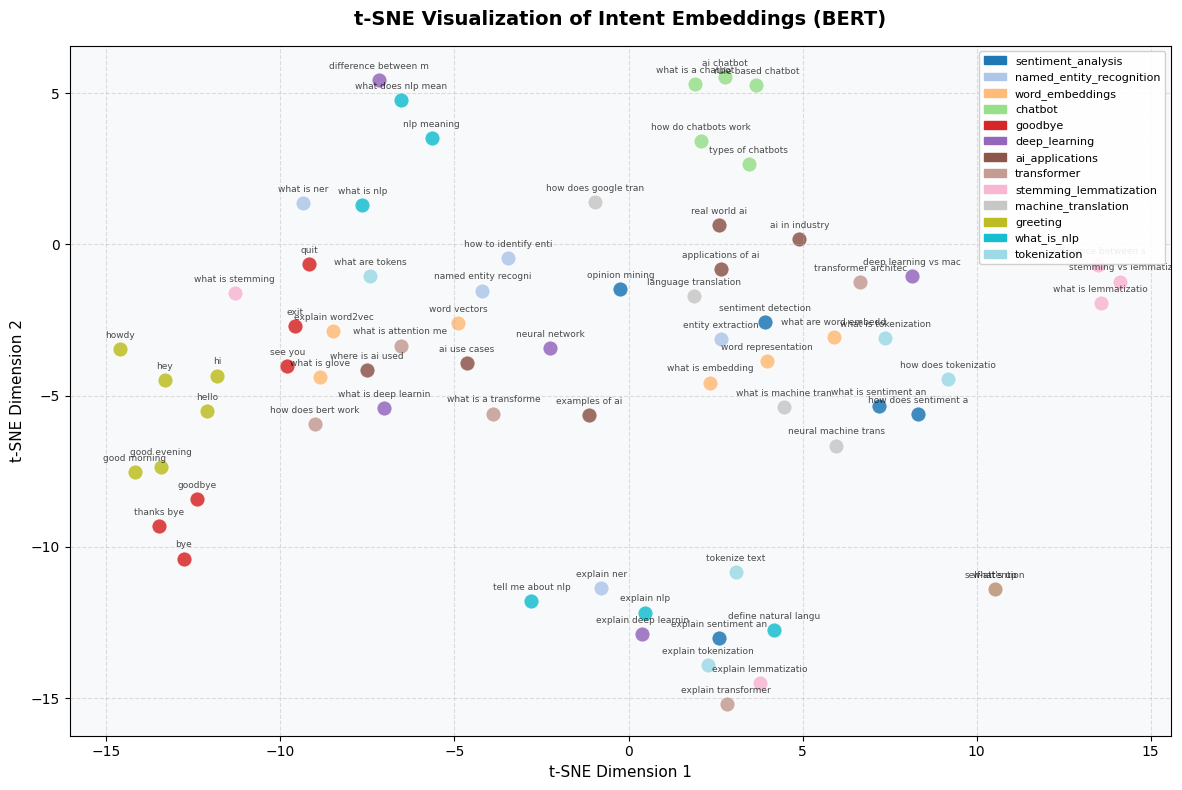

✅ t-SNE visualization saved as 'tsne_embeddings.png'


In [10]:
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
from sklearn.manifold import TSNE

# Run t-SNE to reduce 768-dim embeddings to 2D
tsne = TSNE(n_components=2, perplexity=min(15, len(pattern_embeddings)-1),
            random_state=42, n_iter=1000)
embeddings_2d = tsne.fit_transform(pattern_embeddings)

# Color map for each intent
unique_tags = list(set(pattern_tags))
colors = plt.cm.tab20(np.linspace(0, 1, len(unique_tags)))
tag_to_color = {tag: colors[i] for i, tag in enumerate(unique_tags)}

fig, ax = plt.subplots(figsize=(12, 8))
ax.set_facecolor('#f8f9fa')
fig.patch.set_facecolor('#ffffff')

for i, (x, y) in enumerate(embeddings_2d):
    tag = pattern_tags[i]
    color = tag_to_color[tag]
    ax.scatter(x, y, color=color, s=120, alpha=0.85, edgecolors='white', linewidth=0.8)
    ax.annotate(pattern_texts[i][:20], (x, y),
                fontsize=6.5, alpha=0.7, ha='center',
                xytext=(0, 8), textcoords='offset points')

legend_patches = [mpatches.Patch(color=tag_to_color[t], label=t) for t in unique_tags]
ax.legend(handles=legend_patches, loc='upper right', fontsize=8, framealpha=0.9)
ax.set_title('t-SNE Visualization of Intent Embeddings (BERT)', fontsize=14, fontweight='bold', pad=15)
ax.set_xlabel('t-SNE Dimension 1', fontsize=11)
ax.set_ylabel('t-SNE Dimension 2', fontsize=11)
ax.grid(True, linestyle='--', alpha=0.4)

plt.tight_layout()
plt.savefig('tsne_embeddings.png', dpi=150, bbox_inches='tight')
plt.show()
print("✅ t-SNE visualization saved as 'tsne_embeddings.png'")

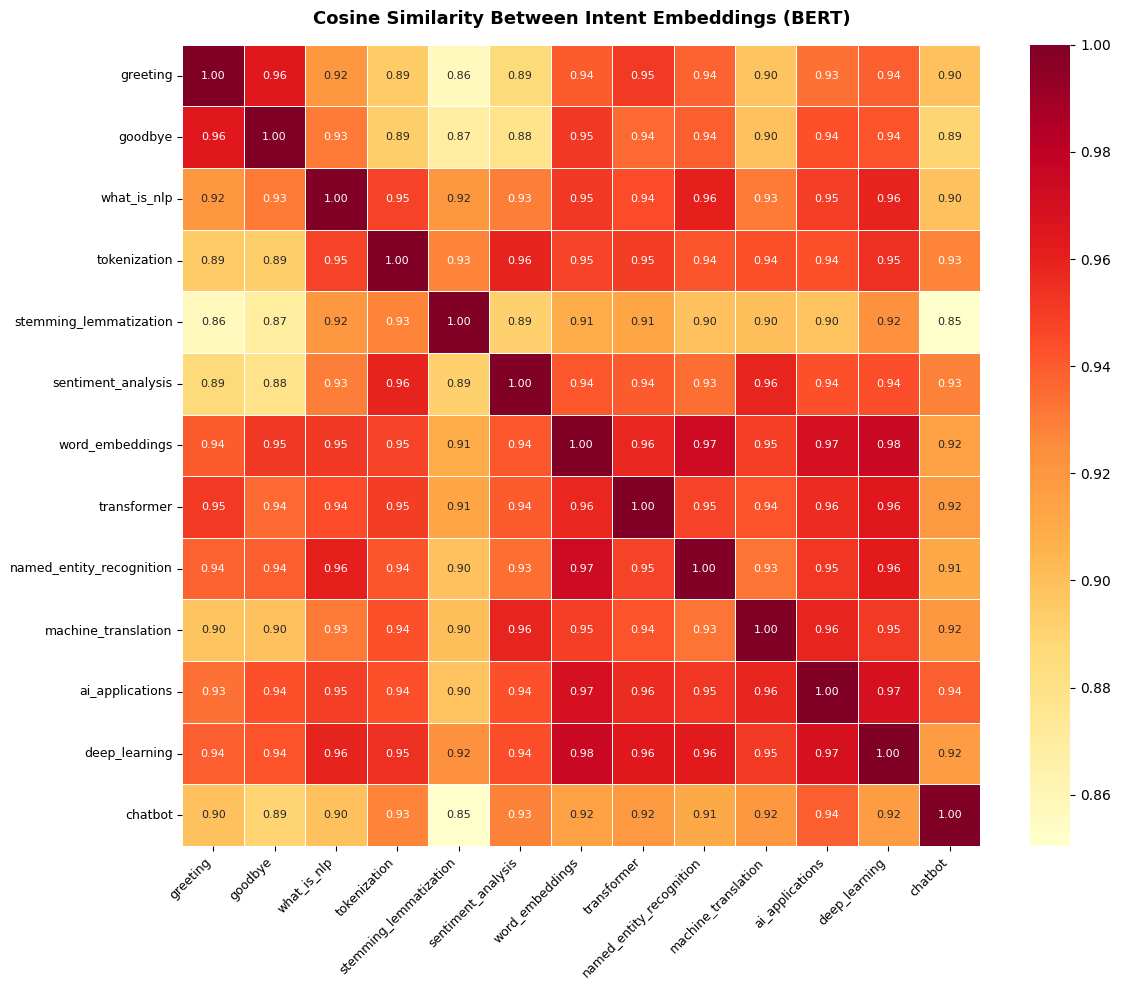

✅ Similarity heatmap saved as 'similarity_heatmap.png'


In [11]:
import seaborn as sns

# Compute mean embedding per intent
intent_labels = [i['tag'] for i in intents if i['tag'] != 'unknown']
intent_mean_embeddings = []

for intent in intents:
    tag = intent['tag']
    if tag == 'unknown':
        continue
    indices = [i for i, t in enumerate(pattern_tags) if t == tag]
    if indices:
        mean_emb = pattern_embeddings[indices].mean(axis=0)
        intent_mean_embeddings.append(mean_emb)

intent_mean_embeddings = np.array(intent_mean_embeddings)
sim_matrix = cosine_similarity(intent_mean_embeddings)

fig, ax = plt.subplots(figsize=(12, 10))
sns.heatmap(
    sim_matrix,
    xticklabels=intent_labels,
    yticklabels=intent_labels,
    annot=True, fmt='.2f',
    cmap='YlOrRd',
    ax=ax,
    linewidths=0.5,
    annot_kws={'size': 8}
)
ax.set_title('Cosine Similarity Between Intent Embeddings (BERT)', fontsize=13, fontweight='bold', pad=15)
ax.set_xticklabels(ax.get_xticklabels(), rotation=45, ha='right', fontsize=9)
ax.set_yticklabels(ax.get_yticklabels(), rotation=0, fontsize=9)

plt.tight_layout()
plt.savefig('similarity_heatmap.png', dpi=150, bbox_inches='tight')
plt.show()
print("✅ Similarity heatmap saved as 'similarity_heatmap.png'")

In [12]:
# Evaluate chatbot confidence on test queries
eval_queries = [
    ("What is NLP?", "what_is_nlp"),
    ("Hello!", "greeting"),
    ("Explain tokenization", "tokenization"),
    ("How does BERT work?", "transformer"),
    ("Word embeddings explained", "word_embeddings"),
    ("Sentiment detection", "sentiment_analysis"),
    ("AI use cases", "ai_applications"),
    ("What is lemmatization?", "stemming_lemmatization"),
    ("Named entity recognition", "named_entity_recognition"),
    ("Types of chatbots", "chatbot"),
]

tags_pred, tags_true, confidences = [], [], []
print(f"{'Query':<35} {'True Intent':<25} {'Predicted':<25} {'Confidence':<10} {'✓'}")
print("-" * 105)

for query, true_tag in eval_queries:
    pred_tag, conf = classify_intent(query)
    correct = "✅" if pred_tag == true_tag else "❌"
    tags_pred.append(pred_tag)
    tags_true.append(true_tag)
    confidences.append(conf)
    print(f"{query:<35} {true_tag:<25} {pred_tag:<25} {conf:.4f}     {correct}")

accuracy = sum(p == t for p, t in zip(tags_pred, tags_true)) / len(tags_true)
print(f"\n📊 Intent Classification Accuracy: {accuracy*100:.1f}%")
print(f"📊 Average Confidence Score     : {np.mean(confidences):.4f}")

Query                               True Intent               Predicted                 Confidence ✓
---------------------------------------------------------------------------------------------------------
What is NLP?                        what_is_nlp               what_is_nlp               1.0000     ✅
Hello!                              greeting                  greeting                  1.0000     ✅
Explain tokenization                tokenization              tokenization              1.0000     ✅
How does BERT work?                 transformer               transformer               1.0000     ✅
Word embeddings explained           word_embeddings           machine_translation       0.9509     ❌
Sentiment detection                 sentiment_analysis        sentiment_analysis        1.0000     ✅
AI use cases                        ai_applications           ai_applications           1.0000     ✅
What is lemmatization?              stemming_lemmatization    stemming_lemmatization  

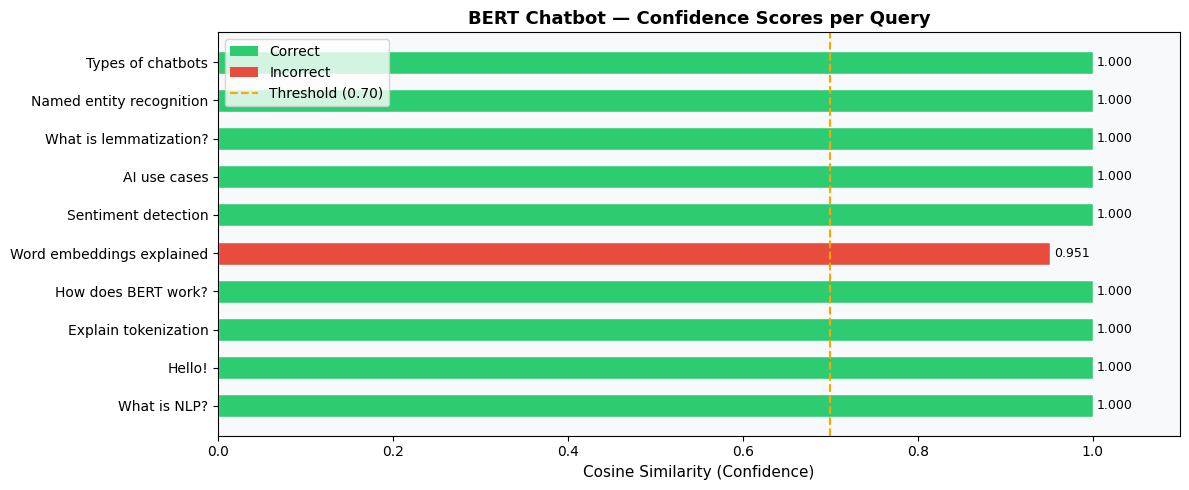

✅ Confidence chart saved as 'confidence_scores.png'


In [13]:
fig, ax = plt.subplots(figsize=(12, 5))

bar_colors = ['#2ecc71' if p == t else '#e74c3c'
              for p, t in zip(tags_pred, tags_true)]

bars = ax.barh([q[:30] for q, _ in eval_queries],
               confidences,
               color=bar_colors, edgecolor='white', height=0.6)

for bar, score in zip(bars, confidences):
    ax.text(bar.get_width() + 0.005, bar.get_y() + bar.get_height()/2,
            f'{score:.3f}', va='center', fontsize=9)

ax.axvline(x=0.70, color='orange', linestyle='--', linewidth=1.5, label='Threshold (0.70)')
ax.set_xlabel('Cosine Similarity (Confidence)', fontsize=11)
ax.set_title('BERT Chatbot — Confidence Scores per Query', fontsize=13, fontweight='bold')
ax.set_xlim(0, 1.1)
ax.legend(fontsize=10)
ax.set_facecolor('#f8f9fa')

from matplotlib.patches import Patch
legend_elements = [
    Patch(facecolor='#2ecc71', label='Correct'),
    Patch(facecolor='#e74c3c', label='Incorrect'),
    plt.Line2D([0], [0], color='orange', linestyle='--', label='Threshold (0.70)')
]
ax.legend(handles=legend_elements, fontsize=10)

plt.tight_layout()
plt.savefig('confidence_scores.png', dpi=150, bbox_inches='tight')
plt.show()
print("✅ Confidence chart saved as 'confidence_scores.png'")

In [14]:
saveprint("=" * 60)
print("  🤖 NLP CHATBOT — Interactive Mode")
print("  Ask about NLP or AI concepts. Type 'quit' to exit.")
print("=" * 60)

while True:
    try:
        user_input = input("\n👤 You: ").strip()
        if not user_input:
            continue
        if user_input.lower() in ['quit', 'exit', 'bye', 'goodbye']:
            print("🤖 Bot: Goodbye! Happy learning! 👋")
            break
        response, tag, confidence = chat(user_input)
        print(f"🤖 Bot [{tag} | {confidence:.3f}]: {response}")
    except KeyboardInterrupt:
        print("\n🤖 Bot: Session ended. Goodbye!")
        break

  🤖 NLP CHATBOT — Interactive Mode
  Ask about NLP or AI concepts. Type 'quit' to exit.

👤 You: wht is nlp
🤖 Bot [what_is_nlp | 0.959]: NLP stands for Natural Language Processing. It is a branch of AI that enables computers to understand, interpret, and generate human language. Examples include chatbots, translation tools, and sentiment analysis.

👤 You: what is machine learning 
🤖 Bot [machine_translation | 0.938]: Machine Translation (MT) uses AI to automatically translate text from one language to another. Modern neural MT uses encoder-decoder transformers. Google Translate and DeepL use these architectures.

👤 You: exit
🤖 Bot: Goodbye! Happy learning! 👋
